# A GPU's junction temperature and cooling response, from power

Fit once using power and the junction sensor. After that, power is the only input.

Heat passes through three layers to reach the coolant:

```
power --> [ die ] --R1--> [ package ] --R2--> [ cold plate ] --R3--> coolant
            C1               C2                  C3
```

Heat flows between layers at (temperature difference) / R, and each layer warms by (heat in − heat out) / C. The whole model is in `gpu_model.h`.

In [1]:
import io, re, shutil, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path('.').resolve()
GPUS = [0, 1, 2, 3]
COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

def load_samples(path):
    return pd.read_csv(path, sep=' ', names=['power_W', 'time_s', 'junction_C'])

def rms_error(predicted, samples):
    readings = samples[samples.junction_C.notna()]
    return np.sqrt(np.mean((np.interp(readings.time_s, predicted.time_s, predicted.junction_C) - readings.junction_C) ** 2))

## Step 1: Fit

`./reproduce.sh` writes one samples file per GPU from the Score-P trace, then runs `fit_gpu`, which writes `gpu_fit.h`.

In [2]:
print(subprocess.run(['./reproduce.sh'], cwd=HERE, capture_output=True, text=True, check=True).stdout)
print((HERE / 'gpu_fit.h').read_text())

Client Version: 2026.02.02+40.gec39a6ec8rochpl-frontier GPU 0: 21215 power samples, 7284 junction readings
rochpl-frontier GPU 1: 21215 power samples, 7426 junction readings
rochpl-frontier GPU 2: 21215 power samples, 5832 junction readings
rochpl-frontier GPU 3: 21215 power samples, 6748 junction readings
hpl-captured-params GPU 0: 12735 power samples, 5390 junction readings
hpl-captured-params GPU 1: 12734 power samples, 5865 junction readings
hpl-captured-params GPU 2: 12733 power samples, 5435 junction readings
hpl-captured-params GPU 3: 12735 power samples, 5672 junction readings
hpl-captured-params-HIP GPU 0: 12862 power samples, 5996 junction readings
hpl-captured-params-HIP GPU 1: 12863 power samples, 5722 junction readings
hpl-captured-params-HIP GPU 2: 12865 power samples, 5676 junction readings
hpl-captured-params-HIP GPU 3: 12862 power samples, 5190 junction readings
hpgmxp GPU 0: 15495 power samples, 4381 junction readings
hpgmxp GPU 1: 15495 power samples, 5823 junction r

## Step 2: Predict from power alone

Without the `sensor` option, `predict_gpu` ignores the junction readings. It only uses power and time.

GPU 0: predicted vs sensor, 0.73 °C RMS
GPU 1: predicted vs sensor, 0.72 °C RMS
GPU 2: predicted vs sensor, 0.78 °C RMS
GPU 3: predicted vs sensor, 0.78 °C RMS


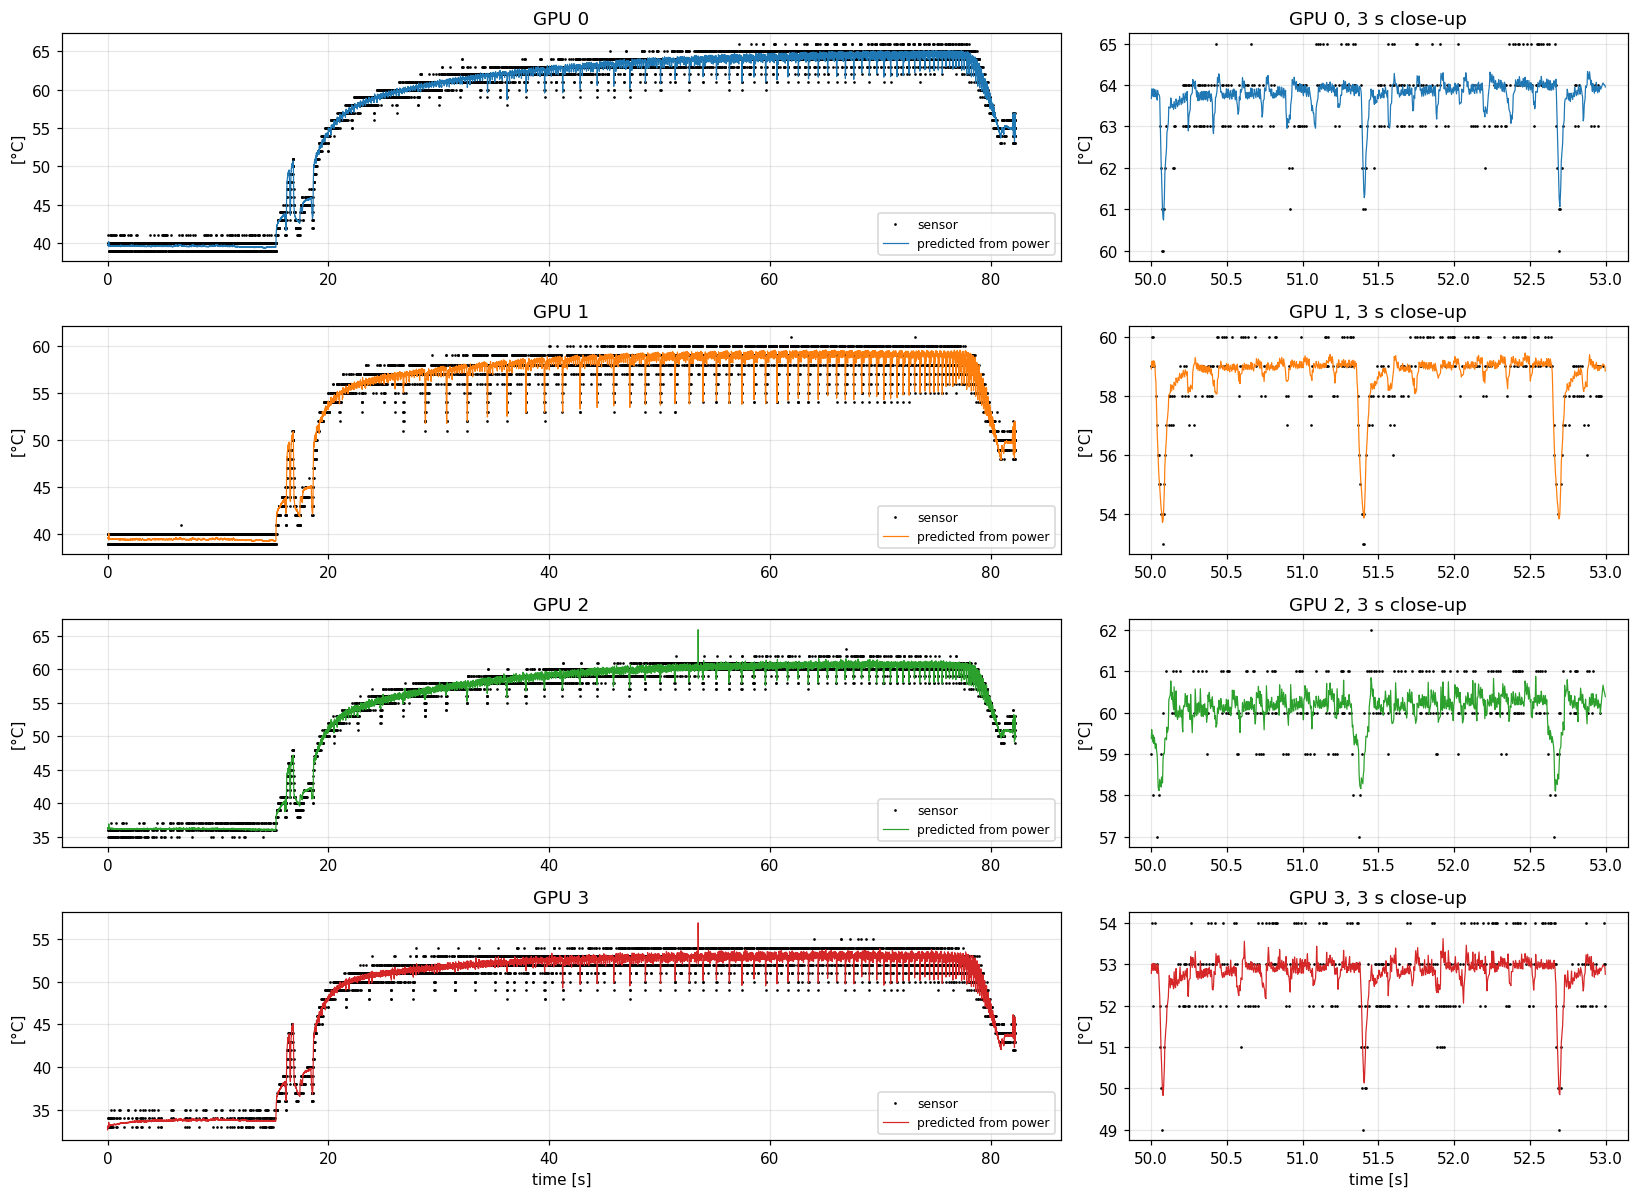

In [3]:
SAMPLES = {g: load_samples(HERE / 'samples' / f'gpu{g}.txt') for g in GPUS}
PREDICTED = {}
for g in GPUS:
    with open(HERE / 'samples' / f'gpu{g}_predicted.csv', 'w') as f:
        subprocess.run(['./predict_gpu', str(g), f'samples/gpu{g}.txt'], cwd=HERE, stdout=f, check=True)
    PREDICTED[g] = pd.read_csv(HERE / 'samples' / f'gpu{g}_predicted.csv')
    print(f"GPU {g}: predicted vs sensor, {rms_error(PREDICTED[g], SAMPLES[g]):.2f} °C RMS")

fig, ax = plt.subplots(4, 2, figsize=(15, 11), gridspec_kw=dict(width_ratios=[2, 1]))
for g in GPUS:
    readings = SAMPLES[g][SAMPLES[g].junction_C.notna()]
    for a, (start, end) in zip(ax[g], [(0, 83), (50, 53)]):
        r = readings[(readings.time_s >= start) & (readings.time_s < end)]
        p = PREDICTED[g][(PREDICTED[g].time_s >= start) & (PREDICTED[g].time_s < end)]
        a.plot(r.time_s, r.junction_C, '.', color='k', ms=1.5, label='sensor')
        a.plot(p.time_s, p.junction_C, color=COLORS[g], lw=0.8, label='predicted from power')
        a.set(ylabel='[°C]', title=f'GPU {g}' if start == 0 else f'GPU {g}, 3 s close-up')
    ax[g, 0].legend(loc='lower right', fontsize=8)
ax[3, 0].set_xlabel('time [s]'); ax[3, 1].set_xlabel('time [s]')
fig.tight_layout(); fig.savefig(HERE / 'junction_prediction.png', bbox_inches='tight')

**How to read this figure.** Black dots are the sensor, which reads in 1 °C steps. The line is the prediction, made from power alone. On the right is a 3 s close-up.

* **It follows the job start, the slow climb, the sharp dips at each stall, and the end of the job.** The error is 0.72–0.78 °C RMS, and the sensor's 1 °C steps account for part of that.
* **The brief spike at about 53.5 s on GPUs 2 and 3** isn't real heating. It's a glitch in the energy counter passing straight through the model, and the sensor doesn't show it.

## Step 3: The cooling response

The same run of `predict_gpu`, also from power alone. **Left:** the heat the GPU puts into the water, against the heat the chip makes, over the whole run (1 s averages of the chip's heat, so the line stays readable). **Middle:** half a second at full load, with the die exit added. **Right:** the water temperature reaching and leaving each GPU.

GPU 0: heat into the water 6.7 -> 36.0 W/cm²; water warms by 0.4 -> 2.3 °C across this GPU
GPU 1: heat into the water 7.1 -> 36.6 W/cm²; water warms by 0.5 -> 2.4 °C across this GPU
GPU 2: heat into the water 6.7 -> 37.0 W/cm²; water warms by 0.4 -> 2.4 °C across this GPU
GPU 3: heat into the water 4.7 -> 36.8 W/cm²; water warms by 0.3 -> 2.4 °C across this GPU
GPU 0, 3 s at full load, swing as a standard deviation: chip 7.89, die exit 2.14, into the water 0.253 W/cm²


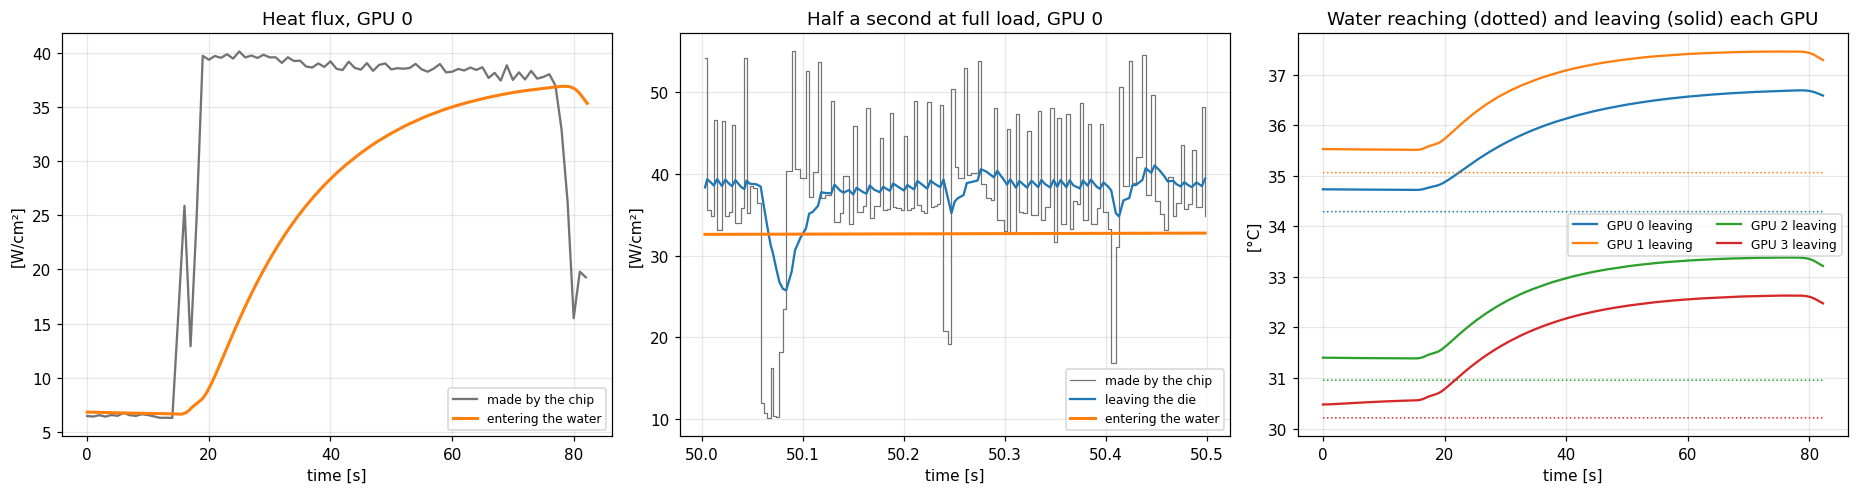

In [4]:
def fig_cooling():
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    p = PREDICTED[0]
    sec = np.floor(p.time_s).astype(int)
    a = ax[0]
    a.plot(np.unique(sec), p.flux_generated_W_cm2.groupby(sec).mean(), color='0.45', lw=1.5, label='made by the chip')
    a.plot(p.time_s, p.flux_to_water_W_cm2, color='tab:orange', lw=2, label='entering the water')
    a.set(xlabel='time [s]', ylabel='[W/cm²]', title='Heat flux, GPU 0'); a.legend(fontsize=8)
    z = (p.time_s >= 50) & (p.time_s < 50.5)
    a = ax[1]
    a.step(p.time_s[z], p.flux_generated_W_cm2[z], where='post', color='0.45', lw=0.8, label='made by the chip')
    a.plot(p.time_s[z], p.flux_die_exit_W_cm2[z], color='tab:blue', lw=1.5, label='leaving the die')
    a.plot(p.time_s[z], p.flux_to_water_W_cm2[z], color='tab:orange', lw=2, label='entering the water')
    a.set(xlabel='time [s]', ylabel='[W/cm²]', title='Half a second at full load, GPU 0'); a.legend(fontsize=8)
    a = ax[2]
    for g in GPUS:
        a.plot(PREDICTED[g].time_s, PREDICTED[g].water_out_C, color=COLORS[g], lw=1.5, label=f'GPU {g} leaving')
        a.plot(PREDICTED[g].time_s, PREDICTED[g].coolant_C, color=COLORS[g], lw=1, ls=':')
    a.set(xlabel='time [s]', ylabel='[°C]', title='Water reaching (dotted) and leaving (solid) each GPU'); a.legend(fontsize=8, ncol=2)
    fig.tight_layout(); fig.savefig(HERE / 'cooling_response.png', bbox_inches='tight')

fig_cooling()
for g in GPUS:
    p = PREDICTED[g]; idle = p.time_s < 14; busy = (p.time_s > 60) & (p.time_s < 75)
    print(f"GPU {g}: heat into the water {p.flux_to_water_W_cm2[idle].mean():.1f} -> {p.flux_to_water_W_cm2[busy].mean():.1f} W/cm²; water warms by {(p.water_out_C - p.coolant_C)[idle].mean():.1f} -> {(p.water_out_C - p.coolant_C)[busy].mean():.1f} °C across this GPU")
b = (PREDICTED[0].time_s > 50) & (PREDICTED[0].time_s < 53)
q = PREDICTED[0][b]
print(f"GPU 0, 3 s at full load, swing as a standard deviation: chip {q.flux_generated_W_cm2.std():.2f}, die exit {q.flux_die_exit_W_cm2.std():.2f}, into the water {q.flux_to_water_W_cm2.std():.3f} W/cm²")

**What this shows.**

* **Left:** the chip's heat jumps almost instantly when the job starts, but the heat entering the water takes far longer to catch up: about 17 s to get 63 % of the way, and 35 s to get 90 %. The layers store heat in the meantime. When the job ends, the water keeps receiving heat after the chip has dropped.
* **Middle:** the fast swings shrink at every layer. Over 3 s at full load, the chip's heat swings by 7.9 W/cm² (standard deviation), the die exit by 2.1, and the heat into the water by only 0.25, most of which is the slow climb.
* **Right:** at full load the water warms by about 2.4 °C passing each GPU, and by 0.3–0.5 °C at idle.

**How far to trust these outputs.**

* **Only the junction temperature was checked against a sensor.** The heat fluxes and water temperatures are what the fitted layers imply, with nothing measured to compare them against.
* **The water's warming depends on an estimate.** `WATER_CAPACITY` (223 W/K, about 3.2 L/min) is one node's estimated share of its cabinet's flow, not something this fit found. Double the flow and the warming halves.
* **The dotted lines are flat here because this run is a single node.** With the `group` option, the coolant moves (Steps 6 and 7).

## Step 4: A fairer test, on data the fit never saw

Step 2 scored the junction on the same trace the model was fitted to. Here the fit only sees the first 50 s, then predicts from 50 s to the end from power alone.

In [5]:
SPLIT_S = 50.0
TEST = HERE / 'samples' / 'first_50s'
TEST.mkdir(exist_ok=True)
for name in ('predict_gpu.c', 'gpu_model.h'):
    shutil.copy(HERE / name, TEST / name)

for g in GPUS:
    first_part = SAMPLES[g][SAMPLES[g].time_s < SPLIT_S]
    first_part[['power_W', 'time_s', 'junction_C']].to_csv(TEST / f'gpu{g}.txt', sep=' ', header=False, index=False, na_rep='nan')

fit_log = subprocess.run([str(HERE / 'fit_gpu'), 'gpu_fit.h'] + [f'gpu{g}.txt' for g in GPUS], cwd=TEST, capture_output=True, text=True, check=True).stdout
print(fit_log)
subprocess.run(['cc', '-O2', 'predict_gpu.c', '-lm', '-o', 'predict_gpu'], cwd=TEST, check=True)

for g in GPUS:
    with open(TEST / f'gpu{g}_predicted.csv', 'w') as f:
        subprocess.run(['./predict_gpu', str(g), str(HERE / 'samples' / f'gpu{g}.txt')], cwd=TEST, stdout=f, check=True)
    p = pd.read_csv(TEST / f'gpu{g}_predicted.csv')
    seen = SAMPLES[g][SAMPLES[g].time_s < SPLIT_S]; unseen = SAMPLES[g][SAMPLES[g].time_s >= SPLIT_S]
    print(f"GPU {g}: error on the 50 s it saw {rms_error(p, seen):.2f} °C; on the {unseen.time_s.max() - SPLIT_S:.0f} s it never saw {rms_error(p, unseen):.2f} °C")

GPU 0: R 0.0156 + 0.0245 + 0.0146 = 0.0546 K/W; C 2.67, 79.6, 1087 J/K; coolant 34.4 °C; power 89 to 575 W; margin 1.6 °C
    error 0.72 °C over 4046 readings; on the last 30% when fitted only on the rest: 0.79 °C
GPU 1: R 0.0164 + 0.0180 + 0.0095 = 0.0439 K/W; C 2.06, 63.5, 1409 J/K; coolant 35.1 °C; power 93 to 574 W; margin 1.5 °C
    error 0.71 °C over 4051 readings; on the last 30% when fitted only on the rest: 0.75 °C
GPU 2: R 0.0158 + 0.0223 + 0.0155 = 0.0535 K/W; C 2.26, 73.9, 820 J/K; coolant 31.0 °C; power 91 to 574 W; margin 1.8 °C
    error 0.77 °C over 3077 readings; on the last 30% when fitted only on the rest: 0.79 °C
GPU 3: R 0.0158 + 0.0187 + 0.0070 = 0.0416 K/W; C 2.82, 66.7, 2372 J/K; coolant 30.2 °C; power 85 to 580 W; margin 1.7 °C
    error 0.78 °C over 3376 readings; on the last 30% when fitted only on the rest: 0.85 °C



GPU 0: error on the 50 s it saw 0.72 °C; on the 32 s it never saw 0.78 °C
GPU 1: error on the 50 s it saw 0.71 °C; on the 32 s it never saw 0.74 °C
GPU 2: error on the 50 s it saw 0.77 °C; on the 32 s it never saw 0.87 °C
GPU 3: error on the 50 s it saw 0.78 °C; on the 32 s it never saw 0.78 °C


**What this shows.** On the 32 s the fit never saw, the error is 0.74–0.87 °C, barely worse than the 0.71–0.78 °C on the part it saw. So the model isn't just memorizing the trace.

**What this doesn't show.**

* **Other jobs and other nodes.** This is one node, one run, and 82 s. The unseen part includes stalls and the end of the job, but no new job start, and it's the same kind of work.
* **Changing coolant.** This step runs as a single node, so its coolant stays steady. Steps 5–7 show the coolant moving.

## Step 5: Estimating the coolant from the GPU's own temperature

The model works out the lift from power alone. So the rest of the junction reading must be the coolant:

$$\text{coolant} = \text{measured junction} - \text{die lift}$$

The only numbers this needs are the GPU's own `R` and `C`. There's nothing about the CDU, the valve or the cabinet. Here it runs on the real rocHPL trace, using the real sensor.

GPU 0: coolant estimated from the sensor: 34.3 °C at idle, 34.3 °C under load (-0.0); range 34.2-34.5 °C


GPU 1: coolant estimated from the sensor: 34.6 °C at idle, 35.1 °C under load (+0.5); range 34.4-35.2 °C
GPU 2: coolant estimated from the sensor: 30.7 °C at idle, 31.0 °C under load (+0.3); range 30.4-31.2 °C
GPU 3: coolant estimated from the sensor: 31.1 °C at idle, 30.4 °C under load (-0.8); range 30.2-31.5 °C


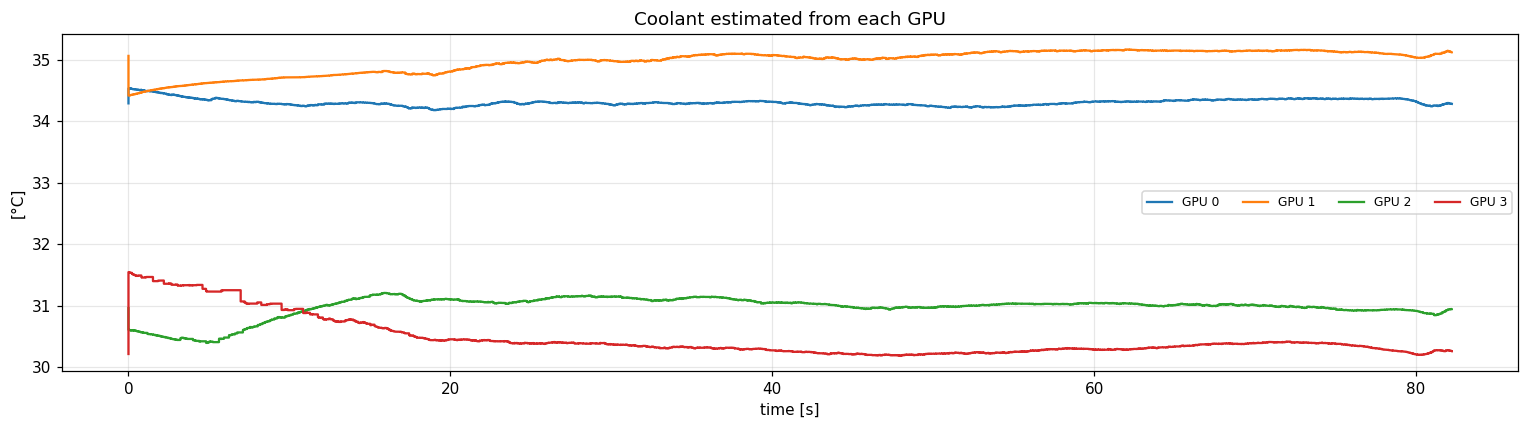

In [6]:
ESTIMATED = {}
for g in GPUS:
    result = subprocess.run(['./predict_gpu', str(g), f'samples/gpu{g}.txt', 'sensor'], cwd=HERE, capture_output=True, text=True, check=True)
    ESTIMATED[g] = pd.read_csv(io.StringIO(result.stdout))
    e = ESTIMATED[g]; start = e.coolant_C[e.time_s < 14].mean(); end = e.coolant_C[(e.time_s > 60) & (e.time_s < 75)].mean()
    print(f"GPU {g}: coolant estimated from the sensor: {start:.1f} °C at idle, {end:.1f} °C under load ({end - start:+.1f}); range {e.coolant_C.min():.1f}-{e.coolant_C.max():.1f} °C")

fig, a = plt.subplots(figsize=(14, 4))
for g in GPUS:
    a.plot(ESTIMATED[g].time_s, ESTIMATED[g].coolant_C, color=COLORS[g], lw=1.5, label=f'GPU {g}')
a.set(xlabel='time [s]', ylabel='[°C]', title='Coolant estimated from each GPU'); a.legend(fontsize=8, ncol=4)
fig.tight_layout(); fig.savefig(HERE / 'coolant_estimate.png', bbox_inches='tight')

**What this shows.** Each GPU's estimate stays within about 0.3 °C or less during the run, while its junction rises 19–25 °C. That's expected here, since one node barely warms the shared coolant. So the rise is correctly put down to the GPU's own power. This is only a basic check, because `R` and `C` were fitted on this same trace.

## Step 6: The coolant moving, from power alone

`cabinet_power_recon_gpu_energy_1ms.csv` has each GPU slot's total power per cabinet every millisecond. Each total ÷ 128 gives the average GPU in that slot, and every sample goes through `predict_gpu` with the `group` option. **No water temperature goes in.** `R` and `C` are unchanged. The GPU's heat into the water drives the coolant, through the 3 water numbers in `gpu_fit.h`.

Those 3 numbers were fitted against this run's measured inlet, up to t = 1400 s. **So the part after t = 1400 s is the test** (the dotted line).

The estimated inlet is the coolant's change added to the inlet's settled value. The estimated outlet is that inlet plus the warming from the GPUs' heat.

cabinet 1: inlet error 0.34 °C (fitted part), 0.28 °C (unseen); peak 32.4 at t = 307 s (real 33.2 at 312 s)
           outlet error 3.38 °C (fitted part), 3.76 °C (unseen); warming on the plateau 7.5 °C, real 11.1 °C
cabinet 2: inlet error 0.35 °C (fitted part), 0.24 °C (unseen); peak 32.3 at t = 307 s (real 33.1 at 313 s)
           outlet error 3.98 °C (fitted part), 4.29 °C (unseen); warming on the plateau 7.5 °C, real 11.8 °C
cabinet 3: inlet error 0.44 °C (fitted part), 0.10 °C (unseen); peak 32.4 at t = 307 s (real 32.9 at 327 s)
           outlet error 4.87 °C (fitted part), 4.95 °C (unseen); warming on the plateau 7.6 °C, real 12.6 °C
cabinet 1 junction, hottest slot: peak 64.8 °C (no sensor to compare with)


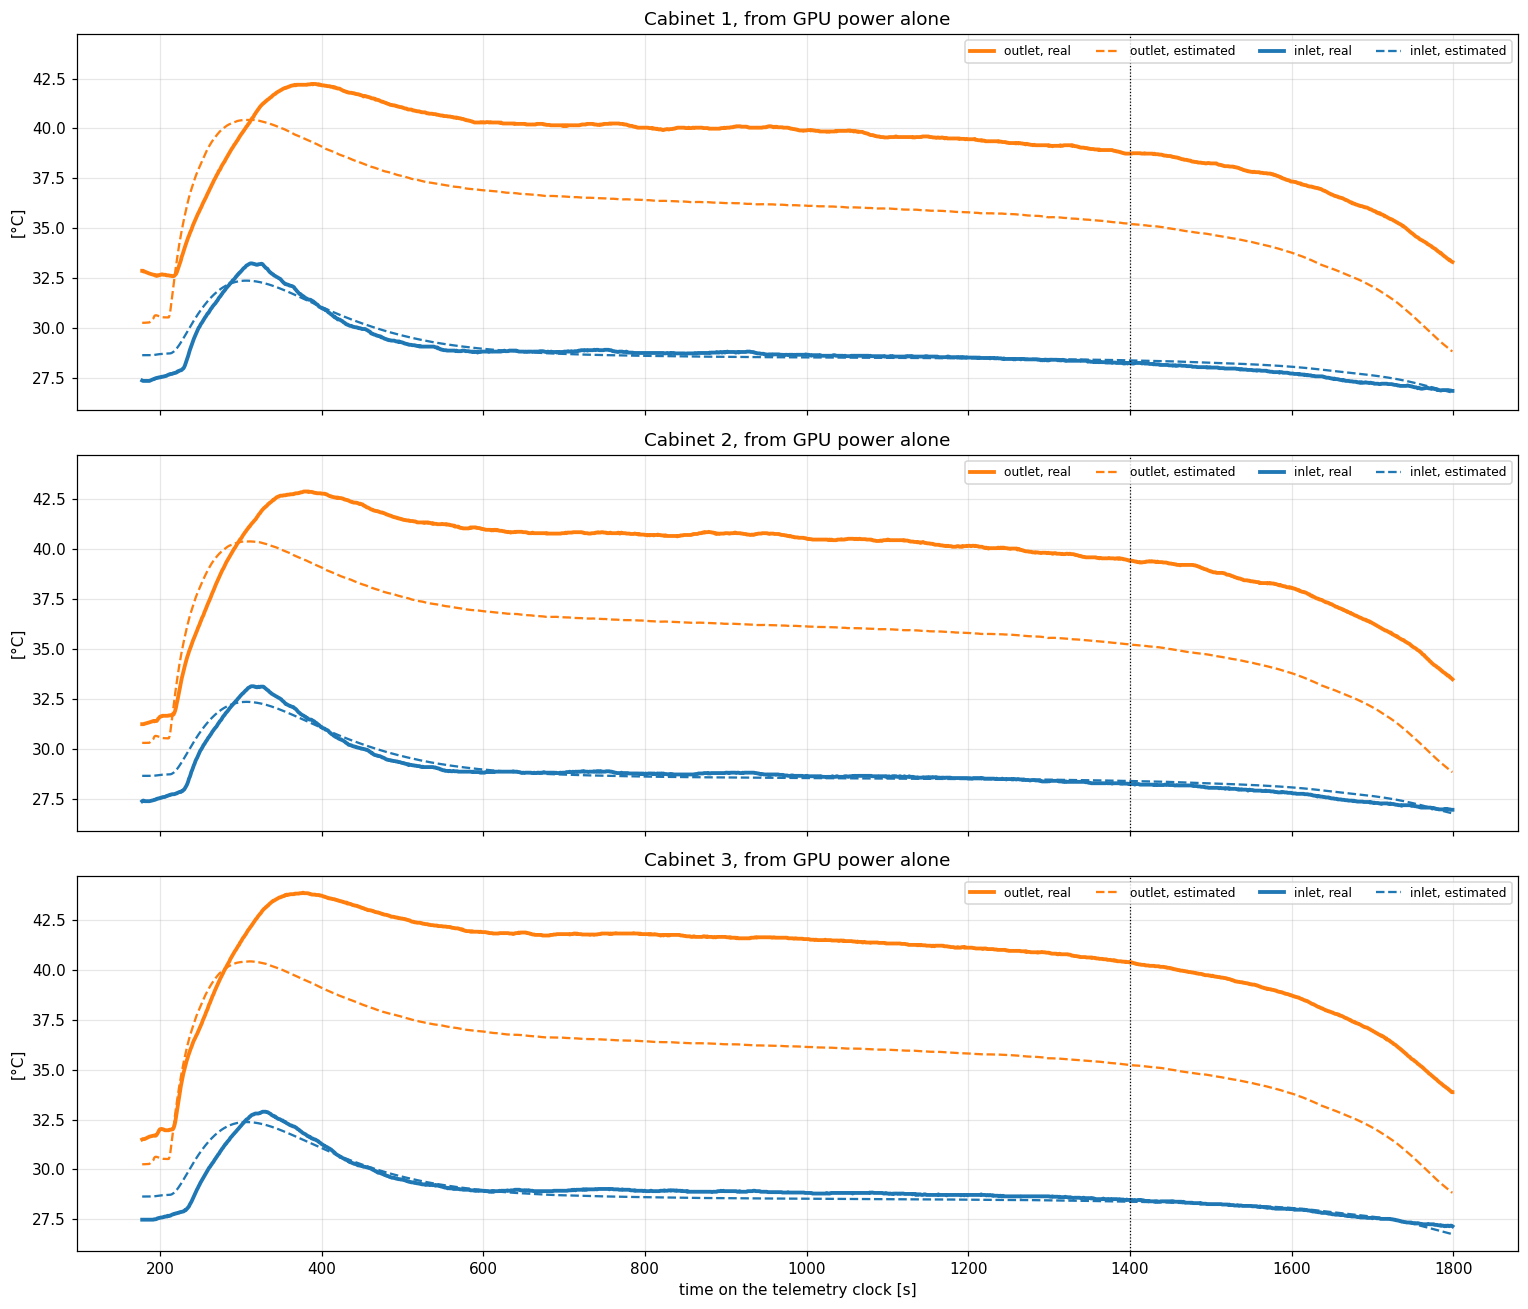

In [7]:
RECON = pd.read_csv(HERE.parent / 'cabinet_power_recon_gpu_energy_1ms.csv')
TELEMETRY = pd.read_csv(HERE.parent / '3Cab_POW.txt', sep=r'\s+', skiprows=11)
t0 = pd.to_datetime(TELEMETRY.TS.iloc[0])
t_tel = (pd.to_datetime(TELEMETRY.TS) - t0).dt.total_seconds().to_numpy()
t_offset = (pd.to_datetime(RECON.utc.iloc[0], utc=True) - t0).total_seconds() - RECON.t_since_job_start_s.iloc[0]
t_gpu = RECON.t_since_job_start_s.to_numpy() + t_offset
overlap = (t_tel >= t_gpu[0]) & (t_tel <= t_gpu[-1])
t = t_tel[overlap]
col = lambda name: TELEMETRY[name].to_numpy(float)[overlap]
NODES, AREA_CM2, WATER_CAPACITY, SETTLED_INLET = 128, 14.48, 223.0, 28.64

INLET, OUTLET, RISE, JUNCTION = {}, {}, {}, {}
for cabinet in (1, 2, 3):
    change, heat, JUNCTION[cabinet] = 0, 0, []
    for slot in GPUS:
        power_W = RECON[f'C{cabinet}_gpu{slot + 1}_energy_W'].to_numpy() / NODES
        text = '\n'.join(f'{p:.4f} {tm:.6f}' for p, tm in zip(power_W, t_gpu))
        result = subprocess.run(['./predict_gpu', str(slot), '/dev/stdin', 'group'], cwd=HERE, input=text, capture_output=True, text=True, check=True)
        out = pd.read_csv(io.StringIO(result.stdout), usecols=['time_s', 'junction_C', 'coolant_C', 'flux_to_water_W_cm2'])
        coolant = np.interp(t, out.time_s, out.coolant_C)
        change = change + (coolant - out.coolant_C.iloc[0] + 0) / len(GPUS)
        heat = heat + np.interp(t, out.time_s, out.flux_to_water_W_cm2) * AREA_CM2 * NODES
        JUNCTION[cabinet].append(np.interp(t, out.time_s, out.junction_C))
    INLET[cabinet] = SETTLED_INLET + change
    RISE[cabinet] = heat / (NODES * WATER_CAPACITY)
    OUTLET[cabinet] = INLET[cabinet] + RISE[cabinet]

rms = lambda x: float(np.sqrt(np.mean(np.square(x))))
fit_part = (t > 200) & (t < 1400); unseen = t >= 1400; peak = (t > 200) & (t < 600); plateau = (t > 600) & (t < 1400)
for c in (1, 2, 3):
    real_in, real_out = col(f'LIT_C{c}'), col(f'LOT_C{c}')
    print(f"cabinet {c}: inlet error {rms((INLET[c] - real_in)[fit_part]):.2f} °C (fitted part), {rms((INLET[c] - real_in)[unseen]):.2f} °C (unseen); peak {INLET[c][peak].max():.1f} at t = {t[peak][np.argmax(INLET[c][peak])]:.0f} s (real {real_in[peak].max():.1f} at {t[peak][np.argmax(real_in[peak])]:.0f} s)")
    print(f"           outlet error {rms((OUTLET[c] - real_out)[fit_part]):.2f} °C (fitted part), {rms((OUTLET[c] - real_out)[unseen]):.2f} °C (unseen); warming on the plateau {RISE[c][plateau].mean():.1f} °C, real {(real_out - real_in)[plateau].mean():.1f} °C")
print(f"cabinet 1 junction, hottest slot: peak {max(j[peak].max() for j in JUNCTION[1]):.1f} °C (no sensor to compare with)")

fig, ax = plt.subplots(3, 1, figsize=(14, 12), sharex=True, sharey=True)
for a, c in zip(ax, (1, 2, 3)):
    a.plot(t, col(f'LOT_C{c}'), color='tab:orange', lw=2.5, label='outlet, real')
    a.plot(t, OUTLET[c], color='tab:orange', lw=1.5, ls='--', label='outlet, estimated')
    a.plot(t, col(f'LIT_C{c}'), color='tab:blue', lw=2.5, label='inlet, real')
    a.plot(t, INLET[c], color='tab:blue', lw=1.5, ls='--', label='inlet, estimated')
    a.axvline(1400, color='k', lw=0.8, ls=':')
    a.set(ylabel='[°C]', title=f'Cabinet {c}, from GPU power alone'); a.legend(fontsize=8, ncol=4, loc='upper right')
ax[2].set_xlabel('time on the telemetry clock [s]')
fig.tight_layout(); fig.savefig(HERE / 'inlet_outlet.png', bbox_inches='tight')

**What this shows.** From GPU power alone, the inlet now moves. It rises after the job starts and settles back, within 0.10–0.28 °C RMS on the part of the run its 3 numbers never saw, and 0.34–0.44 °C on the part they were fitted to. A fixed inlet would be off by about 1 °C on both.

**Where it falls short.**

* **The peak** reads 0.5–0.8 °C low (32.4 against 33.2 °C on cabinet 1).
* **The start of the job.** The model starts settled, while the real water was still recovering from an earlier job, so its inlet starts about 1 °C high.
* **The outlet is 3.4–5 °C low.** The inlet isn't the cause. The GPUs' heat warms the water by 7.5 °C in this model, against a real 11–12.6 °C, because the GPUs are only about two-thirds of a cabinet's heat and this file contains only GPU power.

**How far to trust it.**

* **The test is limited.** It's one run of one cooling group, and the last stretch is the job winding down, which is a gentle test. There's no second job start in the unseen part, so the rise and overshoot were only seen during fitting. A different job on a different day would be the real test.
* **The 3 numbers describe the whole group running this job.** The model assumes the group's other GPUs match this GPU. If other jobs share the cabinets, the response will be wrong, and without junction readings the model can't tell.
* **They were fitted to measured water temperatures.** On a machine without that telemetry, they'd have to be fitted from junction readings during a large job, which hasn't been tried on real data.

## Step 7: The same samples, with and without the junction readings

The same power samples go through the same fitted model. **Without readings** uses only power. **With readings** also uses the junction sensor. **Without readings, whole group** uses only power too, but as if every GPU in the cooling group ran this trace, so the coolant moves. That last one is what-if: this trace really was one node, so its junction is expected to read high against the sensor.

GPU 0: junction error against the sensor: 0.73 °C without readings, 0.73 °C with them; largest difference between the two 0.25 °C; coolant 34.3 °C without, 34.2-34.5 °C with, 34.3-38.4 °C whole group
GPU 1: junction error against the sensor: 0.72 °C without readings, 0.75 °C with them; largest difference between the two 0.65 °C; coolant 35.1 °C without, 34.4-35.2 °C with, 35.1-39.3 °C whole group


GPU 2: junction error against the sensor: 0.78 °C without readings, 0.78 °C with them; largest difference between the two 0.56 °C; coolant 31.0 °C without, 30.4-31.2 °C with, 30.9-35.3 °C whole group
GPU 3: junction error against the sensor: 0.78 °C without readings, 0.79 °C with them; largest difference between the two 1.33 °C; coolant 30.2 °C without, 30.2-31.5 °C with, 30.2-34.9 °C whole group


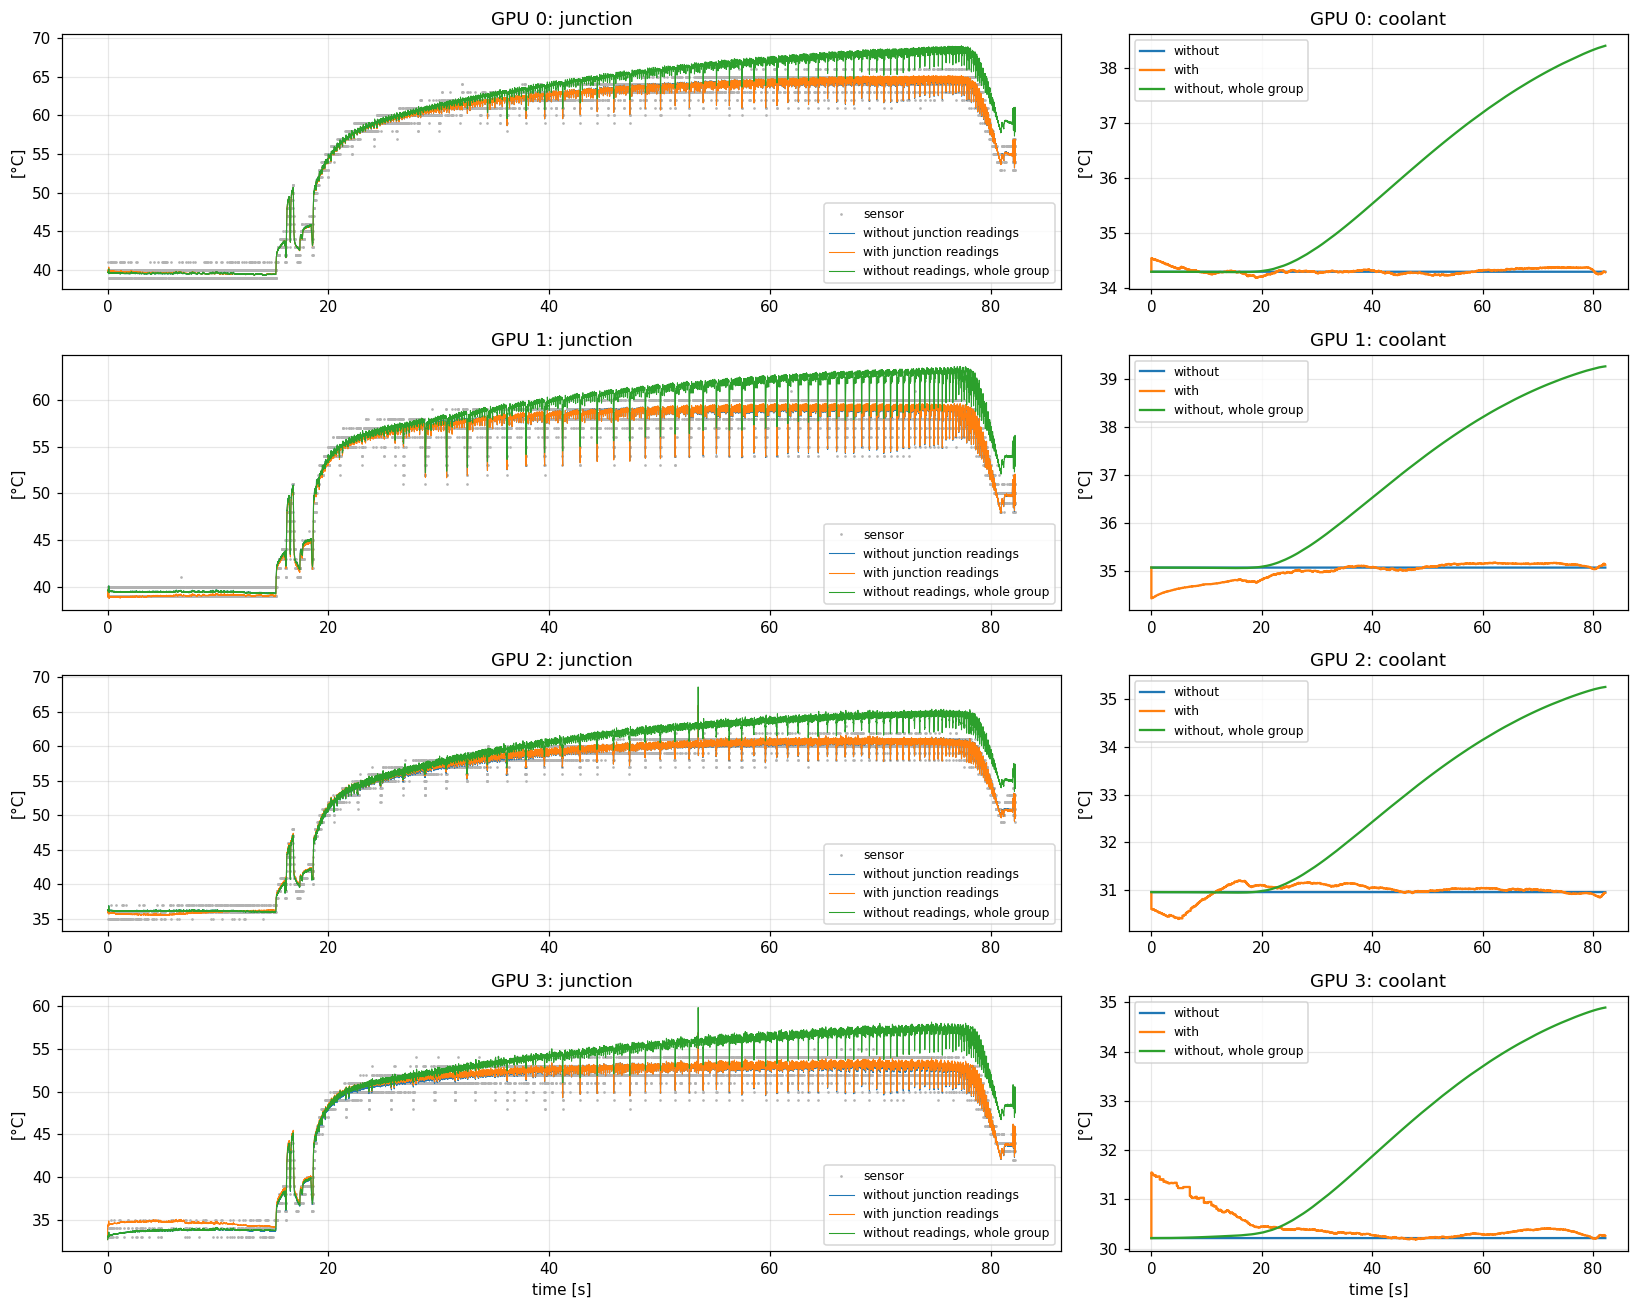

In [8]:
fig, ax = plt.subplots(4, 2, figsize=(15, 12), gridspec_kw=dict(width_ratios=[2, 1]))
for g in GPUS:
    run = lambda *args: pd.read_csv(io.StringIO(subprocess.run(['./predict_gpu', str(g), f'samples/gpu{g}.txt', *args], cwd=HERE, capture_output=True, text=True, check=True).stdout))
    without, with_sensor, group = run(), run('sensor'), run('group')
    readings = SAMPLES[g][SAMPLES[g].junction_C.notna()]
    print(f"GPU {g}: junction error against the sensor: {rms_error(without, SAMPLES[g]):.2f} °C without readings, {rms_error(with_sensor, SAMPLES[g]):.2f} °C with them; "
          f"largest difference between the two {np.abs(without.junction_C - with_sensor.junction_C).max():.2f} °C; "
          f"coolant {without.coolant_C.iloc[-1]:.1f} °C without, {with_sensor.coolant_C.min():.1f}-{with_sensor.coolant_C.max():.1f} °C with, {group.coolant_C.min():.1f}-{group.coolant_C.max():.1f} °C whole group")
    a = ax[g, 0]
    a.plot(readings.time_s, readings.junction_C, '.', color='0.7', ms=1.5, label='sensor')
    a.plot(without.time_s, without.junction_C, color='tab:blue', lw=0.7, label='without junction readings')
    a.plot(with_sensor.time_s, with_sensor.junction_C, color='tab:orange', lw=0.7, label='with junction readings')
    a.plot(group.time_s, group.junction_C, color='tab:green', lw=0.7, label='without readings, whole group')
    a.set(ylabel='[°C]', title=f'GPU {g}: junction'); a.legend(fontsize=8, loc='lower right')
    a = ax[g, 1]
    a.plot(without.time_s, without.coolant_C, color='tab:blue', lw=1.5, label='without')
    a.plot(with_sensor.time_s, with_sensor.coolant_C, color='tab:orange', lw=1.5, label='with')
    a.plot(group.time_s, group.coolant_C, color='tab:green', lw=1.5, label='without, whole group')
    a.set(ylabel='[°C]', title=f'GPU {g}: coolant'); a.legend(fontsize=8)
ax[3, 0].set_xlabel('time [s]'); ax[3, 1].set_xlabel('time [s]')
fig.tight_layout(); fig.savefig(HERE / 'with_and_without_junction.png', bbox_inches='tight')

**What this shows.** On this trace, the two runs are nearly the same. Both are 0.72–0.79 °C from the sensor. At any one moment their junction predictions differ by at most 0.25–1.3 °C, depending on the GPU, because the readings keep nudging the estimated coolant. That estimate stays within a range of 0.3–1.3 °C (note the zoomed-in axes on the right).

That's expected, because the two runs only differ when the real coolant differs from the fitted value. This one-node run barely warms the shared coolant, and `R` and `C` were fitted on this same trace. So this confirms the two modes agree when the coolant is steady, but it can't show the benefit of the readings. Step 6 shows the case where the coolant moves.